# 10 (Lanjutan) — Representasi Kontekstual dengan BERT

**Tujuan praktikum**
1. Mahasiswa memahami perbedaan embedding **statis** (Word2Vec) dan **kontekstual** (BERT).
2. Mahasiswa memahami tokenisasi subword (WordPiece) dan *mean pooling* untuk membuat embedding dokumen.
3. Mahasiswa mampu menerapkan BERT untuk *dense retrieval* (bi-encoder) dan *re-ranking* hasil BM25.
4. Mahasiswa mampu membandingkan kinerja BERT dengan BM25 dan menjelaskan pentingnya *pretraining*.

**Model yang digunakan: IndoBERT.** Notebook ini memakai **IndoBERT** (`indobenchmark/indobert-base-p1`; Wilie dkk., 2020), BERT-base berbahasa Indonesia (12 lapis, 768 dimensi) yang di-pretrain pada korpus Indo4B berisi sekitar 4 miliar kata. Model diunduh otomatis dari Hugging Face saat pertama kali dijalankan (sekitar 500 MB) dan disimpan di cache.

Jika unduhan gagal (misalnya tidak ada koneksi internet), notebook otomatis **melatih BERT mini dari nol** pada korpus praktikum: tokenizer WordPiece, *masked language modeling* (MLM), lalu penyetelan kontrastif tanpa label (SimCSE). BERT mini ini hanya untuk memahami mekanismenya; kualitasnya jauh di bawah IndoBERT.

IndoBERT belum dilatih khusus untuk mengukur kemiripan kalimat, sehingga embedding hasil *mean pooling*-nya belum optimal untuk retrieval. Notebook menyediakan opsi `SIMCSE_INDOBERT = True` untuk menyetel IndoBERT dengan SimCSE pada korpus praktikum (Langkah 2c). Model alternatif yang sudah disetel untuk kemiripan kalimat, misalnya `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`, dapat dicoba dengan mengganti `MODEL_PRETRAINED`.

**Koleksi uji dan metrik sama dengan Bab 4–6.** Notebook ini memakai korpus (`korpus.csv`, 30 dokumen), 8 query (`queries.csv`), penilaian relevansi (`qrels.csv`), dan fungsi `evaluate(run, qrels, k=5)` yang sama dengan notebook TF-IDF, BM25, dan evaluasi. Setiap model mengembalikan 10 dokumen teratas per query, lalu dihitung P@5, R@5, F1@5, AP/MAP, dan nDCG@5. Dengan begitu angka di notebook ini dapat dibandingkan langsung dengan TF-IDF dan BM25.
Satu-satunya perbedaan: BERT menerima teks asli tanpa stemming dan penghapusan stopword, sedangkan TF-IDF, BM25, dan Word2Vec memakai hasil `preprocess`.

In [1]:
# Jalankan sekali jika pustaka belum terpasang:
# !pip install torch transformers tokenizers pandas numpy matplotlib Sastrawi
import re, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel
from stki_utils import corpus_texts, preprocess, BM25Model, TfidfModel, load_queries, load_qrels, evaluate

torch.manual_seed(42)
teks = corpus_texts()
ids = list(teks)
queries, qrels = load_queries(), load_qrels()
bm25 = BM25Model({d: preprocess(t) for d, t in teks.items()})
run_bm25 = {q: [d for d, _ in bm25.search(preprocess(t), k=10)] for q, t in queries.items()}

## Langkah 1 — Memuat model pretrained (atau menyiapkan BERT mini)
Perhatikan bahwa BERT menerima **teks asli** (tanpa stemming dan tanpa penghapusan stopword), karena makna kontekstual justru bergantung pada urutan kata lengkap.

In [2]:
MODEL_PRETRAINED = "indobenchmark/indobert-base-p1"   # IndoBERT
SIMCSE_INDOBERT = False   # True: setel IndoBERT dengan SimCSE di Langkah 2c (lebih lama di CPU)

try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_PRETRAINED)
    model = AutoModel.from_pretrained(MODEL_PRETRAINED)
    PAKAI_PRETRAINED = True
    print("Memakai model pretrained:", MODEL_PRETRAINED,
          f"({sum(p.numel() for p in model.parameters()) / 1e6:.0f} juta parameter)")
except Exception as e:
    PAKAI_PRETRAINED = False
    print("Model pretrained tidak dapat diunduh:", type(e).__name__)
    print("-> melatih BERT mini dari nol pada korpus praktikum (Langkah 2a-2c)")

config.json: 0.00B [00:00, ?B/s]

c:\Users\ASUS\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:130: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--indobenchmark--indobert-base-p1. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Memakai model pretrained: indobenchmark/indobert-base-p1 (124 juta parameter)


model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

## Langkah 2a — (BERT mini) Melatih tokenizer WordPiece
WordPiece memecah kata langka menjadi potongan subword (ditandai `##`), sehingga tidak ada kata yang benar-benar OOV.

In [3]:
kalimat = [s for t in teks.values() for s in re.split(r"(?<=\.)\s+", t.lower())]

if not PAKAI_PRETRAINED:
    from tokenizers import BertWordPieceTokenizer
    from transformers import BertTokenizerFast
    wp = BertWordPieceTokenizer(lowercase=True)
    wp.train_from_iterator(kalimat, vocab_size=1000, min_frequency=1)
    tokenizer = BertTokenizerFast(tokenizer_object=wp._tokenizer)

print("Ukuran kosakata tokenizer:", tokenizer.vocab_size)
for s in ["pembelajaran daring mahasiswa", "telemedisin di daerah terpencil", "pertanain modern"]:
    print(f"{s!r:35s} -> {tokenizer.tokenize(s)}")

Ukuran kosakata tokenizer: 30521
'pembelajaran daring mahasiswa'     -> ['pembelajaran', 'daring', 'mahasiswa']
'telemedisin di daerah terpencil'   -> ['tel', '##eme', '##dis', '##in', 'di', 'daerah', 'terpencil']
'pertanain modern'                  -> ['pert', '##anai', '##n', 'modern']


## Langkah 2b — (BERT mini) Pretraining dengan Masked Language Modeling
Sebanyak 15% token disembunyikan (`[MASK]`) dan model belajar menebaknya dari konteks kiri dan kanan. Arsitektur dibuat sangat kecil (2 lapis, 128 dimensi) agar dapat dilatih di CPU dalam beberapa detik. Sebagai perbandingan, IndoBERT-base memiliki 12 lapis, 768 dimensi, dan dilatih pada sekitar 4 miliar kata.

In [4]:
if not PAKAI_PRETRAINED:
    from transformers import BertConfig, BertForMaskedLM, DataCollatorForLanguageModeling
    config = BertConfig(vocab_size=tokenizer.vocab_size, hidden_size=128, num_hidden_layers=2,
                        num_attention_heads=2, intermediate_size=256, max_position_embeddings=128)
    mlm = BertForMaskedLM(config)
    collator = DataCollatorForLanguageModeling(tokenizer, mlm_probability=0.15)
    encoded = [tokenizer(s, truncation=True, max_length=64)["input_ids"] for s in kalimat]
    opt = torch.optim.AdamW(mlm.parameters(), lr=5e-4)
    g = torch.Generator().manual_seed(0)
    riwayat, t0 = [], time.time()
    mlm.train()
    for step in range(1500):
        idx = torch.randint(len(encoded), (16,), generator=g).tolist()
        batch = collator([{"input_ids": encoded[i]} for i in idx])
        loss = mlm(**batch).loss
        loss.backward(); opt.step(); opt.zero_grad()
        riwayat.append(loss.item())
    print(f"Pelatihan MLM selesai dalam {time.time() - t0:.1f} detik; loss awal {riwayat[0]:.2f}, akhir {np.mean(riwayat[-50:]):.2f}")
    model = mlm.bert   # encoder BERT tanpa kepala MLM
    plt.figure(figsize=(6, 3)); plt.plot(pd.Series(riwayat).rolling(50).mean())
    plt.xlabel("langkah"); plt.ylabel("loss MLM"); plt.title("Kurva loss pretraining BERT mini"); plt.show()

## Langkah 2c — Penyetelan kontrastif SimCSE (BERT mini, opsional untuk IndoBERT)
Keluaran MLM belum dirancang untuk mengukur kemiripan kalimat. **SimCSE tanpa label** memasukkan kalimat yang sama dua kali; karena *dropout*, kedua vektornya sedikit berbeda dan dijadikan pasangan positif, sedangkan kalimat lain dalam batch menjadi negatif. Ini adalah ide dasar di balik model *sentence embedding* seperti Sentence-BERT.

Langkah ini selalu dijalankan untuk BERT mini. Untuk IndoBERT, langkah ini hanya dijalankan jika `SIMCSE_INDOBERT = True`, dengan *learning rate* lebih kecil dan langkah lebih sedikit karena model sudah di-pretrain.

In [5]:
def mean_pooling(batch, hidden):
    mask = batch["attention_mask"].unsqueeze(-1).float()
    return (hidden * mask).sum(1) / mask.sum(1)

if not PAKAI_PRETRAINED or SIMCSE_INDOBERT:
    lr, n_langkah, n_batch = (2e-5, 100, 16) if PAKAI_PRETRAINED else (3e-4, 400, 32)
    unit = kalimat + [t.lower() for t in teks.values()]
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(1)
    model.train()
    for step in range(n_langkah):
        x = [unit[i] for i in torch.randint(len(unit), (n_batch,), generator=g).tolist()]
        b = tokenizer(x, padding=True, truncation=True, max_length=128, return_tensors="pt")
        z1 = F.normalize(mean_pooling(b, model(**b).last_hidden_state), dim=1)
        z2 = F.normalize(mean_pooling(b, model(**b).last_hidden_state), dim=1)
        loss = F.cross_entropy(z1 @ z2.T / 0.05, torch.arange(len(x)))
        loss.backward(); opt.step(); opt.zero_grad()
    print(f"SimCSE selesai, loss akhir {loss.item():.3f}")
model.eval();

## Langkah 3 — Embedding kontekstual: satu kata, banyak vektor
Word2Vec memberi **satu** vektor untuk setiap kata. BERT memberi vektor yang berbeda tergantung kalimatnya. Kita bandingkan vektor kata *pembelajaran* pada tiga kalimat.

In [6]:
def vektor_kata(kalimat, kata):
    kalimat = kalimat.lower()
    awal = kalimat.index(kata); akhir = awal + len(kata)
    b = tokenizer(kalimat, return_tensors="pt", return_offsets_mapping=True)
    offsets = b.pop("offset_mapping")[0].tolist()
    with torch.no_grad():
        h = model(**b).last_hidden_state[0]
    # ambil semua subword yang berada di dalam rentang karakter kata target
    posisi = [i for i, (a, z) in enumerate(offsets) if z > a and a >= awal and z <= akhir]
    return h[posisi].mean(0)

contoh = {
    "A (pendidikan)": "Pembelajaran daring memanfaatkan platform digital untuk mahasiswa.",
    "B (pendidikan)": "Kurikulum Merdeka menyesuaikan pembelajaran dengan kebutuhan siswa.",
    "C (kecerdasan buatan)": "Pembelajaran mesin digunakan dalam pengenalan wajah dan rekomendasi produk.",
}
V = {k: vektor_kata(s, "pembelajaran") for k, s in contoh.items()}
sim = pd.DataFrame({a: {b: float(F.cosine_similarity(V[a], V[b], dim=0)) for b in V} for a in V})
sim.round(3)

,A (pendidikan),B (pendidikan),C (kecerdasan buatan)
A (pendidikan),1.000,0.579,0.548
B (pendidikan),0.579,1.000,0.461
C (kecerdasan buatan),0.548,0.461,1.000


Pada Word2Vec semua sel tabel ini akan bernilai 1, karena *pembelajaran* (atau stem-nya *ajar*) hanya punya satu vektor. Pada BERT nilainya kurang dari 1 karena konteks kalimat ikut membentuk vektor. Dengan IndoBERT, kalimat A dan B (sama-sama pendidikan) diharapkan lebih mirip satu sama lain dibanding dengan C. Jika yang berjalan adalah BERT mini, perhatikan apakah pola ini muncul; model yang dilatih dari 120 kalimat belum tentu menangkap makna, dan kemiripan vektornya bisa lebih dipengaruhi posisi kata dalam kalimat.

## Langkah 4 — Dense retrieval (bi-encoder)
Setiap dokumen dan query dikodekan **secara terpisah** menjadi satu vektor (mean pooling), lalu diurutkan dengan cosine similarity. Vektor dokumen dapat dihitung sekali dan disimpan (dalam praktik di *vector database* seperti FAISS).

In [7]:
def encode(texts, batch_size=16):
    out = []
    for i in range(0, len(texts), batch_size):
        b = tokenizer(texts[i:i + batch_size], padding=True, truncation=True, max_length=256, return_tensors="pt")
        with torch.no_grad():
            out.append(F.normalize(mean_pooling(b, model(**b).last_hidden_state), dim=1))
    return torch.cat(out).numpy()

doc_emb = encode([teks[d] for d in ids])
print("Matriks embedding dokumen:", doc_emb.shape)

def dense_search(query, k=10):
    skor = doc_emb @ encode([query])[0]
    urut = np.argsort(-skor)[:k]
    return [(ids[i], float(skor[i])) for i in urut]

run_dense = {q: [d for d, _ in dense_search(t)] for q, t in queries.items()}
pd.DataFrame(dense_search(queries["Q8"], k=5), columns=["doc_id", "cosine"]).round(3)

Matriks embedding dokumen: (30, 768)


,doc_id,cosine
0,D25,0.468
1,D26,0.419
2,D29,0.382
3,D24,0.377
4,D19,0.344


## Langkah 5 — Re-ranking hasil BM25
Pola yang umum di sistem pencarian modern: BM25 mengambil kandidat dengan cepat (misalnya 10–100 dokumen), lalu model neural mengurutkan ulang kandidat tersebut. Di sini skor akhir adalah gabungan skor BM25 ternormalisasi dan cosine BERT.

In [8]:
def rerank_run(lam, n_kandidat=10):
    run = {}
    for q, t in queries.items():
        kandidat = bm25.search(preprocess(t), k=n_kandidat)
        mx = kandidat[0][1]
        qv = encode([t])[0]
        skor = {d: lam * s / mx + (1 - lam) * float(doc_emb[ids.index(d)] @ qv) for d, s in kandidat}
        run[q] = sorted(skor, key=lambda d: (-skor[d], d))
    return run

sweep = pd.DataFrame({lam: evaluate(rerank_run(lam), qrels, k=5).loc["Rata-rata", ["AP", "nDCG@5"]]
                      for lam in [0.0, 0.5, 0.7, 0.9, 1.0]}).T
sweep.index.name = "lambda (bobot BM25)"
sweep.rename(columns={"AP": "MAP"})

,MAP,nDCG@5
lambda (bobot BM25),,
0.0,0.7923,0.8548
0.5,0.7498,0.8630
0.7,0.7590,0.8657
0.9,0.7791,0.8727
1.0,0.7756,0.8668


## Langkah 6 — Perbandingan dengan BM25

In [9]:
nama_model = (("IndoBERT + SimCSE" if SIMCSE_INDOBERT else "IndoBERT") if "indobert" in MODEL_PRETRAINED.lower()
              else MODEL_PRETRAINED) if PAKAI_PRETRAINED else "BERT mini (dilatih lokal)"
ringkasan = pd.DataFrame({
    "BM25": evaluate(run_bm25, qrels, k=5).loc["Rata-rata"],
    f"Dense {nama_model}": evaluate(run_dense, qrels, k=5).loc["Rata-rata"],
    "BM25 + re-ranking BERT (lambda=0,9)": evaluate(rerank_run(0.9), qrels, k=5).loc["Rata-rata"],
}).T.rename(columns={"AP": "MAP"})
ringkasan[["P@5", "MAP", "nDCG@5"]]

,P@5,MAP,nDCG@5
BM25,0.500,0.7756,0.8668
Dense IndoBERT,0.475,0.8074,0.8560
"BM25 + re-ranking BERT (lambda=0,9)",0.500,0.7791,0.8727


## Langkah 7 — Perbandingan semua model pada koleksi uji yang sama
Tabel berikut mengumpulkan model dari Bab 4 (TF-IDF), Bab 5 (BM25), Bab 9 (Word2Vec), dan Bab 10 (BERT). Semua dijalankan pada korpus, query, dan qrels yang sama, lalu dievaluasi dengan fungsi `evaluate(run, qrels, k=5)` yang sama. Model Word2Vec dilatih ulang di sini dengan parameter yang sama seperti notebook 09 agar notebook ini dapat dijalankan sendiri.

In [12]:
import re, hashlib
from gensim.models import Word2Vec

docs_pp = {d: preprocess(t) for d, t in teks.items()}

# Bab 4: TF-IDF / VSM
tfidf = TfidfModel(docs_pp)
run_tfidf = {q: [d for d, _ in tfidf.search(preprocess(t), k=10)] for q, t in queries.items()}

# Bab 9: Word2Vec Skip-gram (parameter sama dengan notebook 09)
kalimat_pp = [k for k in (preprocess(s) for t in teks.values() for s in re.split(r"(?<=\.)\s+", t)) if k]
w2v = Word2Vec(kalimat_pp, sg=1, vector_size=50, window=5, min_count=1, epochs=300, seed=42, workers=1,
               hashfxn=lambda s: int(hashlib.md5(s.encode()).hexdigest()[:8], 16)).wv

def w2v_embed(tokens, pakai_idf):
    vs = [w2v[t] * (tfidf.idf.get(t, 1.0) if pakai_idf else 1.0) for t in tokens if t in w2v]
    v = np.mean(vs, axis=0)
    return v / np.linalg.norm(v)

D_w2v = {d: w2v_embed(t, False) for d, t in docs_pp.items()}
D_w2v_idf = {d: w2v_embed(t, True) for d, t in docs_pp.items()}
run_w2v_dense, run_w2v_hybrid = {}, {}
for q, t in queries.items():
    qt = preprocess(t)
    s_dense = {d: float(v @ w2v_embed(qt, False)) for d, v in D_w2v.items()}
    run_w2v_dense[q] = sorted(s_dense, key=lambda d: (-s_dense[d], d))[:10]
    b = dict(bm25.search(qt, k=len(docs_pp))); mx = max(b.values())
    qv = w2v_embed(qt, True)
    s_hyb = {d: 0.7 * b.get(d, 0) / mx + 0.3 * float(v @ qv) for d, v in D_w2v_idf.items()}
    run_w2v_hybrid[q] = sorted(s_hyb, key=lambda d: (-s_hyb[d], d))[:10]

semua = {
    "TF-IDF / VSM (Bab 4)": run_tfidf,
    "BM25 (Bab 5)": run_bm25,
    "Dense Word2Vec (Bab 9)": run_w2v_dense,
    "Hybrid BM25 + Word2Vec, lambda=0,7 (Bab 9)": run_w2v_hybrid,
    f"Dense {nama_model} (Bab 10)": run_dense,
    "BM25 + re-ranking BERT, lambda=0,9 (Bab 10)": rerank_run(0.9),
}
perbandingan = pd.DataFrame({n: evaluate(r, qrels, k=5).loc["Rata-rata"] for n, r in semua.items()}).T
perbandingan = perbandingan.rename(columns={"AP": "MAP"})[["P@5", "R@5", "MAP", "nDCG@5"]]
perbandingan

,P@5,R@5,MAP,nDCG@5
TF-IDF / VSM (Bab 4),0.500,0.8125,0.7620,0.8622
BM25 (Bab 5),0.500,0.8125,0.7756,0.8668
Dense Word2Vec (Bab 9),0.500,0.8125,0.7482,0.7980
"Hybrid BM25 + Word2Vec, lambda=0,7 (Bab 9)",0.525,0.8542,0.8131,0.8793
Dense IndoBERT (Bab 10),0.475,0.7604,0.8074,0.8560
"BM25 + re-ranking BERT, lambda=0,9 (Bab 10)",0.500,0.8125,0.7791,0.8727


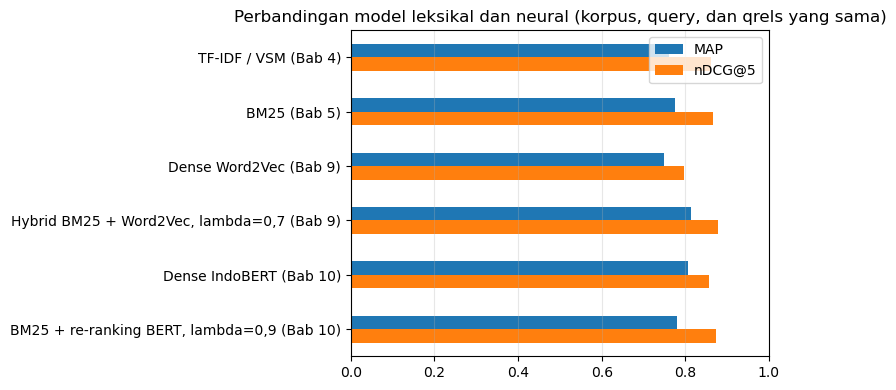

,TF-IDF / VSM (Bab 4),BM25 (Bab 5),Dense Word2Vec (Bab 9),"Hybrid BM25 + Word2Vec, lambda=0,7 (Bab 9)",Dense IndoBERT (Bab 10),"BM25 + re-ranking BERT, lambda=0,9 (Bab 10)"
Q1,0.750,0.750,0.750,0.750,1.000,0.750
Q2,0.618,0.618,0.643,0.618,0.747,0.618
Q3,0.667,0.667,0.667,0.767,1.000,0.667
Q4,0.556,0.556,0.806,0.806,0.792,0.667
Q5,0.867,1.000,1.000,1.000,0.444,0.917
Q6,0.833,0.810,0.421,0.810,0.810,0.810
Q7,1.000,1.000,1.000,1.000,1.000,1.000
Q8,0.806,0.806,0.700,0.756,0.667,0.806


In [13]:
ax = perbandingan[["MAP", "nDCG@5"]].plot.barh(figsize=(8, 4))
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.grid(axis="x", alpha=.3)
ax.set_title("Perbandingan model leksikal dan neural (korpus, query, dan qrels yang sama)")
plt.tight_layout(); plt.show()

# AP per query untuk melihat di query mana model neural membantu atau merugikan
from stki_utils import average_precision
pd.DataFrame({n: {q: average_precision(r[q], set(qrels[q])) for q in queries} for n, r in semua.items()}).round(3)

**Catatan hasil.** Jika notebook ini berjalan dengan BERT mini (tanpa akses ke IndoBERT), dense retrieval jauh di bawah BM25 dan re-ranking belum membantu. Ini bukan kelemahan arsitektur BERT, melainkan bukti bahwa kekuatan BERT berasal dari **pretraining pada data berukuran sangat besar**: 120 kalimat tidak cukup untuk mempelajari bahasa. Jalankan ulang notebook dengan koneksi internet agar IndoBERT dipakai, lalu bandingkan hasilnya (Tugas 1). Hasil BERT mini dapat sedikit berbeda setiap kali notebook dijalankan karena pelatihannya melibatkan proses acak.

## Tugas 10
1. Jalankan notebook dengan koneksi internet agar IndoBERT dipakai, sekali dengan `SIMCSE_INDOBERT = False` dan sekali dengan `True`. Bandingkan MAP dan nDCG@5 keduanya serta BERT mini dengan TF-IDF dan BM25 memakai tabel di Langkah 7. Lalu ganti `MODEL_PRETRAINED` dengan `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`. Mengapa IndoBERT tanpa penyetelan kalimat bisa kalah dari model yang sudah disetel untuk kemiripan kalimat?
2. Ganti mean pooling dengan vektor token `[CLS]`. Bagaimana pengaruhnya?
3. Implementasikan re-ranking dengan **cross-encoder** (misalnya `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1`) yang membaca pasangan (query, dokumen) sekaligus. Bandingkan dengan bi-encoder dari sisi kualitas dan waktu komputasi.
4. Hitung berapa lama `encode` untuk 30 dokumen, lalu perkirakan waktunya untuk 1 juta dokumen. Mengapa sistem produksi memakai indeks vektor seperti FAISS?
5. Diskusikan: kapan BM25 tetap lebih unggul daripada dense retrieval (misalnya untuk kode produk, nama orang, atau istilah langka)?

In [12]:
# Tulis jawaban Anda di sini